In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import yfinance as yf

In [2]:
df = pd.read_excel("Stock position Excel.xlsx")
df

,Symbol,Description,Qty (Quantity),Price Chng $ (Price Change $),Price,Price Chng % (Price Change %),Day Chng % (Day Change %),Cost Basis,Asset Type
0,AAPL,APPLE INC,1.9082,-1.1288,332.5612,-0.0034,-0.0034,600.48,Equity
1,AVGO,BROADCOM INC,2.4837,1.3400,356.4800,0.0038,0.0038,1016.59,Equity
2,BE,BLOOM ENERGY CORP CLASS A,0.5739,1.3500,290.5000,0.0047,0.0046,132.98,Equity
3,CVS,CVS HEALTH CORP,3.1662,-0.1100,86.3500,-0.0013,-0.0013,300.00,Equity
4,ETN,EATON CORP PLC F,2.4283,-0.7127,435.3973,-0.0016,-0.0016,999.96,Equity
5,GOOGL,ALPHABET INC CLASS A,4.1296,-0.4800,343.0200,-0.0014,-0.0014,1398.25,Equity
6,JNJ,JOHNSON & JOHNSON,1.0549,-0.1135,255.9165,-0.0004,-0.0004,274.98,Equity
7,MSFT,MICROSOFT CORP,4.1610,-1.6800,515.8500,-0.0032,-0.0032,1711.56,Equity
8,NVDA,NVIDIA CORP,20.4883,1.9400,235.8900,0.0083,0.0083,4646.46,Equity
9,ORCL,ORACLE CORP,1.4971,0.7600,143.0600,0.0053,0.0054,184.97,Equity


In [3]:
df.columns

Index(['Symbol', 'Description', 'Qty (Quantity)',
       'Price Chng $ (Price Change $)', 'Price',
       'Price Chng % (Price Change %)', 'Day Chng % (Day Change %)',
       'Cost Basis', 'Asset Type'],
      dtype='object')

In [4]:
Equity = df["Cost Basis"].sum()
Equity

np.float64(20687.92)

In [5]:
df["weight"] = df["Cost Basis"] / 20687.92
df

,Symbol,Description,Qty (Quantity),Price Chng $ (Price Change $),Price,Price Chng % (Price Change %),Day Chng % (Day Change %),Cost Basis,Asset Type,weight
0,AAPL,APPLE INC,1.9082,-1.1288,332.5612,-0.0034,-0.0034,600.48,Equity,0.029026
1,AVGO,BROADCOM INC,2.4837,1.3400,356.4800,0.0038,0.0038,1016.59,Equity,0.049139
2,BE,BLOOM ENERGY CORP CLASS A,0.5739,1.3500,290.5000,0.0047,0.0046,132.98,Equity,0.006428
3,CVS,CVS HEALTH CORP,3.1662,-0.1100,86.3500,-0.0013,-0.0013,300.00,Equity,0.014501
4,ETN,EATON CORP PLC F,2.4283,-0.7127,435.3973,-0.0016,-0.0016,999.96,Equity,0.048335
5,GOOGL,ALPHABET INC CLASS A,4.1296,-0.4800,343.0200,-0.0014,-0.0014,1398.25,Equity,0.067588
6,JNJ,JOHNSON & JOHNSON,1.0549,-0.1135,255.9165,-0.0004,-0.0004,274.98,Equity,0.013292
7,MSFT,MICROSOFT CORP,4.1610,-1.6800,515.8500,-0.0032,-0.0032,1711.56,Equity,0.082732
8,NVDA,NVIDIA CORP,20.4883,1.9400,235.8900,0.0083,0.0083,4646.46,Equity,0.224598
9,ORCL,ORACLE CORP,1.4971,0.7600,143.0600,0.0053,0.0054,184.97,Equity,0.008941


# 1. Creating the Weights and Returns

In [6]:
weight = df["weight"].to_list()
stocks = df["Symbol"].to_list()

In [7]:
shares = pd.Series(df["Qty (Quantity)"].values, index = df["Symbol"])
shares

Symbol
AAPL      1.9082
AVGO      2.4837
BE        0.5739
CVS       3.1662
ETN       2.4283
GOOGL     4.1296
JNJ       1.0549
MSFT      4.1610
NVDA     20.4883
ORCL      1.4971
GRID      2.2424
SMH       0.0441
VHT       4.1726
VOO       5.5624
VTI       6.2059
VXUS     17.8430
dtype: float64

In [8]:
tickers = df["Symbol"].to_list()
tickers

['AAPL',
 'AVGO',
 'BE',
 'CVS',
 'ETN',
 'GOOGL',
 'JNJ',
 'MSFT',
 'NVDA',
 'ORCL',
 'GRID',
 'SMH',
 'VHT',
 'VOO',
 'VTI',
 'VXUS']

In [9]:
def stock_data(ticker):
    t = yf.download(ticker, start = "2021-10-01", end = "", interval = "1d", auto_adjust = True, progress = False, timeout = 30, threads = False)["Close"]
    return t.dropna()
stock_data_df = stock_data(tickers)
stock_data_df

Ticker,AAPL,AVGO,BE,CVS,ETN,GOOGL,GRID,JNJ,MSFT,NVDA,ORCL,SMH,VHT,VOO,VTI,VXUS
Date,,,,,,,,,,,,,,,,
2021-10-01,139.136673,44.611431,18.469999,71.221649,139.407913,135.255920,88.731934,139.557098,277.457184,20.651043,83.581429,124.431725,230.215073,372.080322,210.008682,54.441940
2021-10-04,135.713150,43.567902,16.910000,71.001404,137.288834,132.399612,87.491806,138.470016,271.708374,19.645470,83.134369,121.191040,226.627396,367.503052,206.846252,53.875553
2021-10-05,137.634659,44.434753,18.430000,70.857384,139.972397,134.740829,88.078743,138.783112,277.130890,20.361315,85.211342,122.893860,227.659103,371.073578,208.777298,54.201645
2021-10-06,138.502716,44.742329,18.700001,70.442253,140.379562,136.268295,87.643265,139.070068,281.305634,20.609232,85.071625,123.267403,227.315216,372.723663,209.644867,53.884140
2021-10-07,139.760910,45.212841,19.160000,71.331787,142.433914,137.912674,88.959160,140.313705,282.975555,20.982586,85.975060,124.800430,230.066345,375.930573,211.659882,54.502007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09,336.640015,361.540009,280.500000,86.160004,429.649994,351.660004,180.889999,261.440002,535.070007,229.279999,141.399994,603.330017,319.010010,715.590027,381.940002,84.820000
2026-10-12,340.970001,354.730011,262.279999,87.739998,426.690002,352.720001,178.699997,263.730011,541.150024,226.320007,137.389999,590.989990,320.670013,715.130005,381.570007,84.440002
2026-10-13,341.269989,357.309998,263.450012,87.550003,428.309998,353.779999,179.250000,248.610001,543.450012,228.520004,143.199997,588.119995,316.369995,715.200012,381.320007,84.540001


In [10]:
shares = shares.reindex(stock_data_df.columns)
shares

Ticker
AAPL      1.9082
AVGO      2.4837
BE        0.5739
CVS       3.1662
ETN       2.4283
GOOGL     4.1296
GRID      2.2424
JNJ       1.0549
MSFT      4.1610
NVDA     20.4883
ORCL      1.4971
SMH       0.0441
VHT       4.1726
VOO       5.5624
VTI       6.2059
VXUS     17.8430
dtype: float64

In [11]:
def port(data,share):
    p = data.dot(share)
    return p
    
portfolio = port(stock_data_df, shares)
portfolio = pd.DataFrame(portfolio).rename(columns = {0: "Portfolio"})
portfolio

,Portfolio
Date,
2021-10-01,8868.849004
2021-10-04,8721.765192
2021-10-05,8828.214362
2021-10-06,8865.818168
2021-10-07,8957.375102
...,...
2026-10-09,21508.571505
2026-10-12,21442.558062
2026-10-13,21489.098726


In [12]:
portfolio["Month"] = portfolio.index.to_period("M")
portfolio

,Portfolio,Month
Date,,
2021-10-01,8868.849004,2021-10
2021-10-04,8721.765192,2021-10
2021-10-05,8828.214362,2021-10
2021-10-06,8865.818168,2021-10
2021-10-07,8957.375102,2021-10
...,...,...
2026-10-09,21508.571505,2026-10
2026-10-12,21442.558062,2026-10
2026-10-13,21489.098726,2026-10


### Importing the market data (tech heavy = QQQ)

In [13]:
def benchmark(ticker):
    b = yf.download(ticker, start = "2021-10-01", end = "", progress = False, auto_adjust = True, timeout = 30)["Close"]
    return b
benchmark = benchmark("VOO")
benchmark

Ticker,VOO
Date,
2021-10-01,372.080383
2021-10-04,367.503021
2021-10-05,371.073517
2021-10-06,372.723633
2021-10-07,375.930511
...,...
2026-10-12,715.130005
2026-10-13,715.200012
2026-10-14,707.429993


In [14]:
benchmark["Month"] = benchmark.index.to_period("M")
benchmark

Ticker,VOO,Month
Date,,
2021-10-01,372.080383,2021-10
2021-10-04,367.503021,2021-10
2021-10-05,371.073517,2021-10
2021-10-06,372.723633,2021-10
2021-10-07,375.930511,2021-10
...,...,...
2026-10-12,715.130005,2026-10
2026-10-13,715.200012,2026-10
2026-10-14,707.429993,2026-10


### Warning: Always try to merge with the index (date + month) instead of purely month

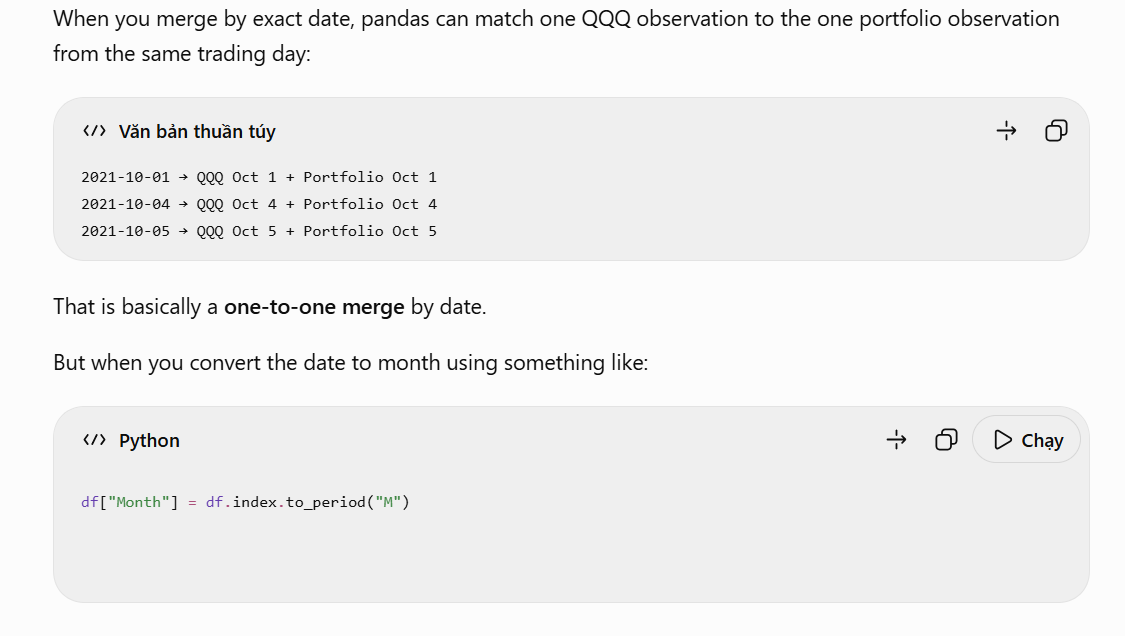
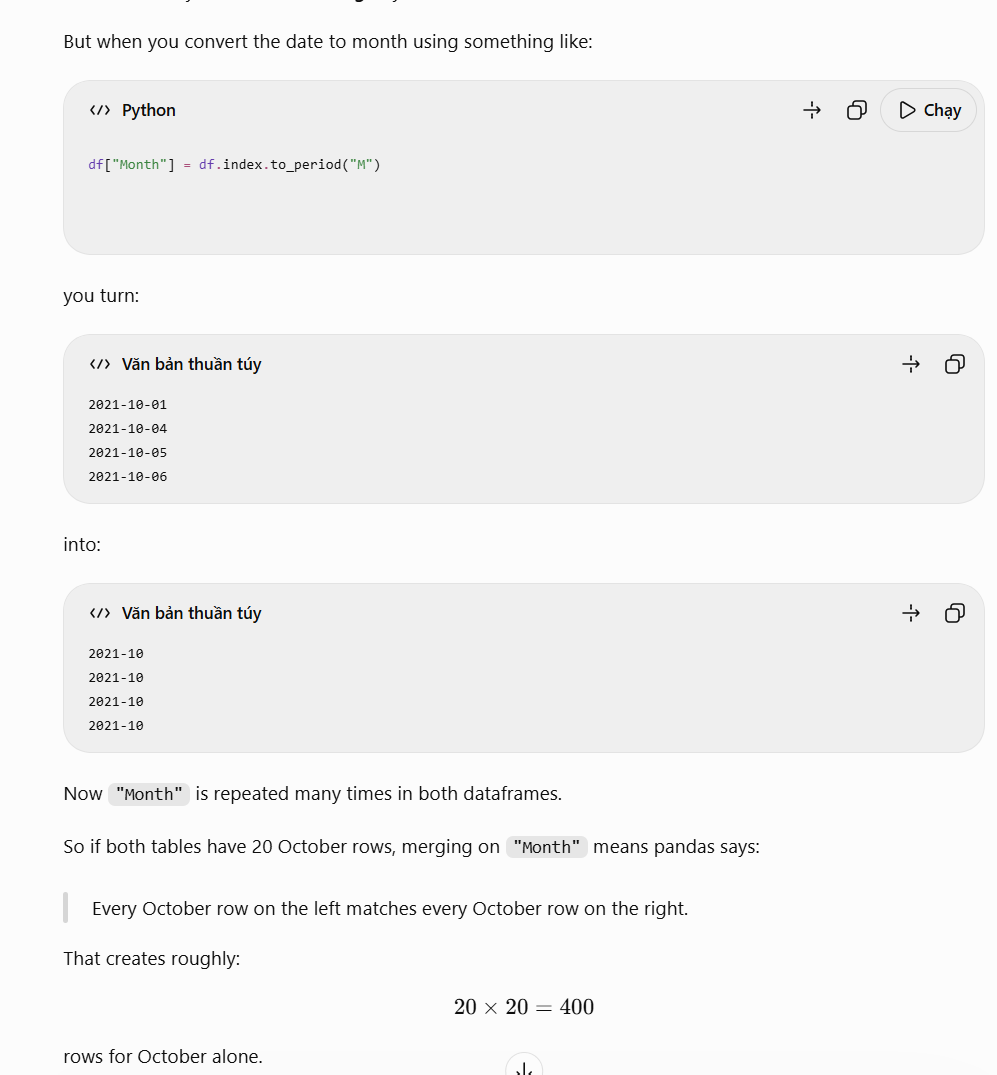

In [15]:
joint_b_p = portfolio[["Portfolio"]].merge(
    benchmark[["VOO"]],
    left_index=True,
    right_index=True,
    how="inner"
)

# Remove incomplete observations
joint_b_p = joint_b_p.dropna()

# Create Month column from Date index
joint_b_p["Month"] = joint_b_p.index.to_period("M")

joint_b_p

,Portfolio,VOO,Month
Date,,,
2021-10-01,8868.849004,372.080383,2021-10
2021-10-04,8721.765192,367.503021,2021-10
2021-10-05,8828.214362,371.073517,2021-10
2021-10-06,8865.818168,372.723633,2021-10
2021-10-07,8957.375102,375.930511,2021-10
...,...,...,...
2026-10-09,21508.571505,715.590027,2026-10
2026-10-12,21442.558062,715.130005,2026-10
2026-10-13,21489.098726,715.200012,2026-10


In [16]:
joint_b_p[["P_ret", "B_ret"]] = joint_b_p[["Portfolio", "VOO"]].pct_change()
joint_b_p

,Portfolio,VOO,Month,P_ret,B_ret
Date,,,,,
2021-10-01,8868.849004,372.080383,2021-10,NaN,NaN
2021-10-04,8721.765192,367.503021,2021-10,-0.016584,-0.012302
2021-10-05,8828.214362,371.073517,2021-10,0.012205,0.009716
2021-10-06,8865.818168,372.723633,2021-10,0.004260,0.004447
2021-10-07,8957.375102,375.930511,2021-10,0.010327,0.008604
...,...,...,...,...,...
2026-10-09,21508.571505,715.590027,2026-10,0.006670,0.006059
2026-10-12,21442.558062,715.130005,2026-10,-0.003069,-0.000643
2026-10-13,21489.098726,715.200012,2026-10,0.002170,0.000098


In [17]:
monthly_join_compound = joint_b_p.groupby("Month")[["P_ret","B_ret"]].agg(lambda x: (1+ x).prod() - 1)
monthly_join_compound.rename(columns = {"P_ret":"p_ret_compound" , "B_ret": "b_ret_compound"}, inplace = True)
monthly_join_compound

,p_ret_compound,b_ret_compound
Month,,
2021-10,0.076291,0.057727
2021-11,0.001385,-0.007343
2021-12,0.036390,0.045603
2022-01,-0.063970,-0.052409
2022-02,-0.024879,-0.029805
...,...,...
2026-06,-0.037996,-0.009605
2026-07,0.016020,-0.000233
2026-08,0.036522,0.026564


In [18]:
new_joint = joint_b_p.merge(monthly_join_compound, on = "Month", how = "left")

In [19]:
new_joint

,Portfolio,VOO,Month,P_ret,B_ret,p_ret_compound,b_ret_compound
0,8868.849004,372.080383,2021-10,NaN,NaN,0.076291,0.057727
1,8721.765192,367.503021,2021-10,-0.016584,-0.012302,0.076291,0.057727
2,8828.214362,371.073517,2021-10,0.012205,0.009716,0.076291,0.057727
3,8865.818168,372.723633,2021-10,0.004260,0.004447,0.076291,0.057727
4,8957.375102,375.930511,2021-10,0.010327,0.008604,0.076291,0.057727
...,...,...,...,...,...,...,...
1260,21508.571505,715.590027,2026-10,0.006670,0.006059,-0.004021,0.012228
1261,21442.558062,715.130005,2026-10,-0.003069,-0.000643,-0.004021,0.012228
1262,21489.098726,715.200012,2026-10,0.002170,0.000098,-0.004021,0.012228
1263,21114.173947,707.429993,2026-10,-0.017447,-0.010864,-0.004021,0.012228


# 2. Groupby and construct Alpha

In [20]:
beta = new_joint.groupby("Month").apply(lambda x: x["P_ret"].cov(x["B_ret"])/ x["B_ret"].var()) # Important to understand what it returns
beta_df = pd.DataFrame(beta).reset_index()
beta_df

# NOTE: Don't .agg(mean) this since it will ruin the sole purpose of cov and var => they need the data to vary (compressing means no good)

C:\Users\hotru\AppData\Local\Temp\ipykernel_14188\2454832937.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  beta = new_joint.groupby("Month").apply(lambda x: x["P_ret"].cov(x["B_ret"])/ x["B_ret"].var()) # Important to understand what it returns


,Month,0
0,2021-10,1.020862
1,2021-11,1.076581
2,2021-12,1.090224
3,2022-01,1.045363
4,2022-02,1.109687
...,...,...
56,2026-06,1.307458
57,2026-07,1.428501
58,2026-08,1.367473
59,2026-09,1.198650


In [21]:
beta_data = new_joint.merge(beta_df, on = "Month")
beta_data.set_index("Month", inplace = True)

In [22]:
beta_data.rename(columns = {0:"Beta"}, inplace = True)
beta_data.drop(columns = ["VOO", "Portfolio", "P_ret", "B_ret"], inplace = True)
#beta_data_monthly = beta_data.groupby(beta_data.index).agg("mean").reset_index()

In [23]:
beta_data

,p_ret_compound,b_ret_compound,Beta
Month,,,
2021-10,0.076291,0.057727,1.020862
2021-10,0.076291,0.057727,1.020862
2021-10,0.076291,0.057727,1.020862
2021-10,0.076291,0.057727,1.020862
2021-10,0.076291,0.057727,1.020862
...,...,...,...
2026-10,-0.004021,0.012228,1.563538
2026-10,-0.004021,0.012228,1.563538
2026-10,-0.004021,0.012228,1.563538


In [24]:
beta_data["Beta"].describe()

count    1265.000000
mean        1.191435
std         0.199357
min         0.943442
25%         1.045363
50%         1.139605
75%         1.303407
max         1.978707
Name: Beta, dtype: float64

In [25]:
rf_rates_annual = 0.045 # We are assuming this is EAR
rf_rates_monthly = (1 + rf_rates_annual)**(1/12) - 1 # => Converts to APR and then / 12
rf_rates_daily = (1 + rf_rates_annual)**(1/252) - 1

monthly_data = beta_data.groupby(beta_data.index).agg("mean").reset_index()
monthly_data["Beta"] = monthly_data["Beta"].shift(1)
monthly_data

,Month,p_ret_compound,b_ret_compound,Beta
0,2021-10,0.076291,0.057727,NaN
1,2021-11,0.001385,-0.007343,1.020862
2,2021-12,0.036390,0.045603,1.076581
3,2022-01,-0.063970,-0.052409,1.090224
4,2022-02,-0.024879,-0.029805,1.045363
...,...,...,...,...
56,2026-06,-0.037996,-0.009605,1.478864
57,2026-07,0.016020,-0.000233,1.307458
58,2026-08,0.036522,0.026564,1.428501
59,2026-09,0.008134,-0.003161,1.367473


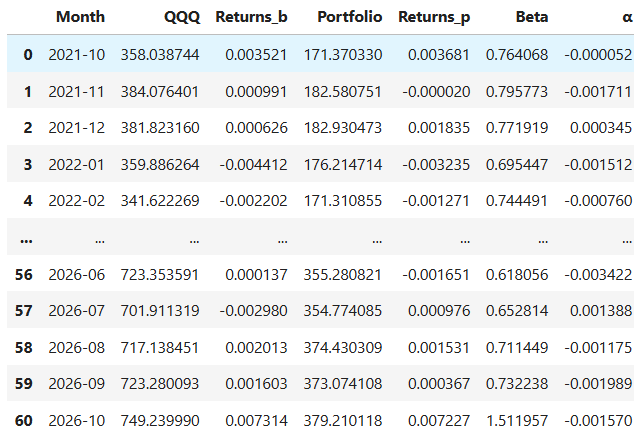

In [26]:
monthly_data["α"] = monthly_data["p_ret_compound"] - (rf_rates_monthly + monthly_data["Beta"]*(monthly_data["b_ret_compound"]-rf_rates_monthly))
monthly_data

,Month,p_ret_compound,b_ret_compound,Beta,α
0,2021-10,0.076291,0.057727,NaN,NaN
1,2021-11,0.001385,-0.007343,1.020862,0.008958
2,2021-12,0.036390,0.045603,1.076581,-0.012423
3,2022-01,-0.063970,-0.052409,1.090224,-0.006502
4,2022-02,-0.024879,-0.029805,1.045363,0.006445
...,...,...,...,...,...
56,2026-06,-0.037996,-0.009605,1.478864,-0.022032
57,2026-07,0.016020,-0.000233,1.307458,0.017454
58,2026-08,0.036522,0.026564,1.428501,0.000150
59,2026-09,0.008134,-0.003161,1.367473,0.013806


In [27]:
monthly_data["α"].describe()

count    60.000000
mean      0.002785
std       0.015957
min      -0.031383
25%      -0.008292
50%       0.005064
75%       0.013967
max       0.037605
Name: α, dtype: float64

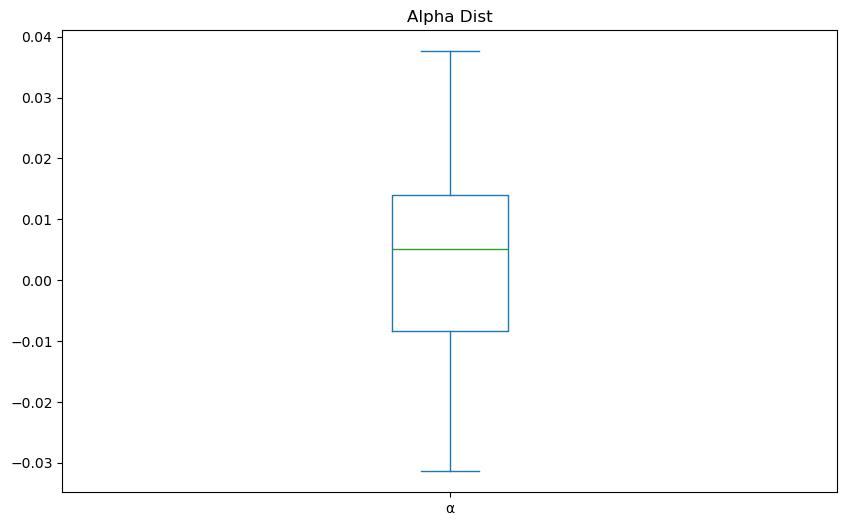

In [28]:
plt.figure(figsize=(10, 6))

monthly_data["α"].plot(kind='box', title='Alpha Dist')
plt.show()

In [29]:
monthly_data.to_csv("monthly_stock_metrics")

In [30]:
monthly_data = monthly_data.dropna()
n = 60
N = 10000

mean_alpha = []
for i in range(N):
    alpha = monthly_data["α"].sample(n, replace = True)
    mean_alpha.append(alpha.mean())
samp_dist = pd.DataFrame({"Average α": mean_alpha})
samp_dist

,Average α
0,0.004592
1,0.003313
2,0.002092
3,0.006922
4,0.001152
...,...
9995,0.001541
9996,0.003300
9997,0.005644
9998,0.002692


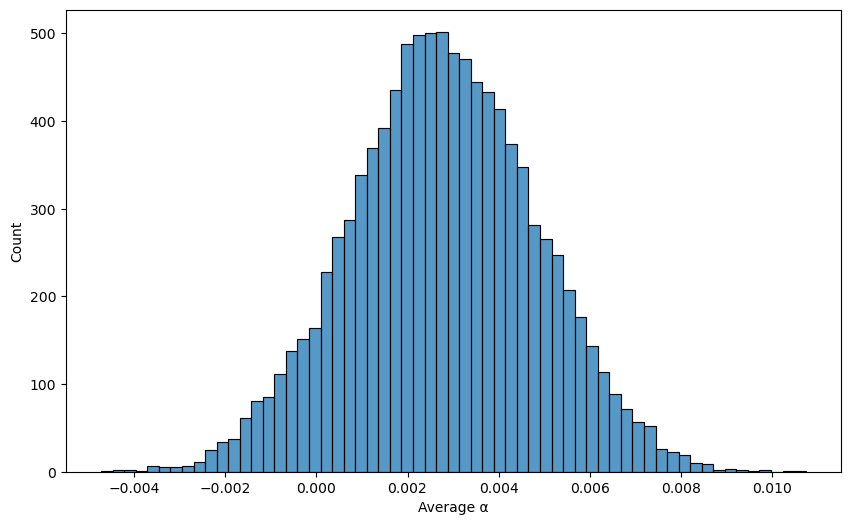

In [31]:
plt.figure(figsize=(10, 6))

sns.histplot(data = samp_dist, x = "Average α")

plt.show()

# 3. Hypothesis Testing

In [32]:
monthly_data["Positive Alpha"] = monthly_data["α"] > 0
monthly_data

C:\Users\hotru\AppData\Local\Temp\ipykernel_14188\248909631.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  monthly_data["Positive Alpha"] = monthly_data["α"] > 0


,Month,p_ret_compound,b_ret_compound,Beta,α,Positive Alpha
1,2021-11,0.001385,-0.007343,1.020862,0.008958,True
2,2021-12,0.036390,0.045603,1.076581,-0.012423,False
3,2022-01,-0.063970,-0.052409,1.090224,-0.006502,False
4,2022-02,-0.024879,-0.029805,1.045363,0.006445,True
5,2022-03,0.036232,0.037892,1.109687,-0.005413,False
6,2022-04,-0.100704,-0.087844,1.111085,-0.002694,False
7,2022-05,-0.001827,0.002588,1.024083,-0.004388,False
8,2022-06,-0.072931,-0.082645,1.009842,0.010563,True
9,2022-07,0.087409,0.091991,1.011283,-0.005578,False
10,2022-08,-0.053068,-0.041289,1.075402,-0.008388,False


In [33]:
percentage_pos_alpha = monthly_data["Positive Alpha"].mean()
percentage_pos_alpha

np.float64(0.5666666666666667)

In [34]:
monthly_data.to_csv("monthly_stock_metrics")

In [35]:
# Sampler — draw one sample of n (one vector per device)
n = 60
pop_stk1 = pd.DataFrame({"stk1": np.repeat([1, 0], [5, 5])})


N = 10001   # samples collected so far
mean_stk1_v = []
for i in range(N):
    stk1 = pop_stk1["stk1"].sample(n, replace=True)
    mean_stk1_v.append(stk1.mean())
    
samp_dist_alpha_average = pd.DataFrame({"mean_stk1_v": mean_stk1_v})
samp_dist_alpha_average

,mean_stk1_v
0,0.500000
1,0.516667
2,0.450000
3,0.516667
4,0.400000
...,...
9996,0.350000
9997,0.450000
9998,0.550000
9999,0.616667


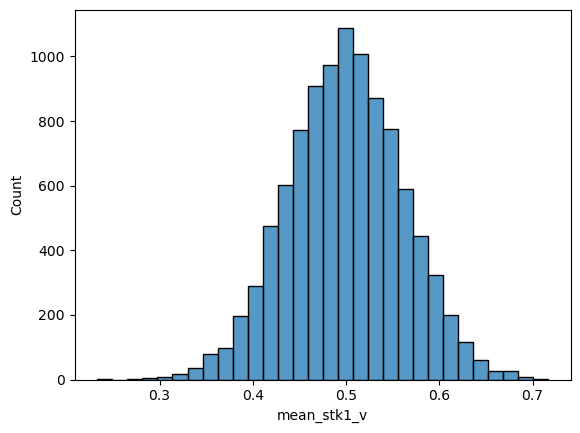

In [36]:
sns.histplot(data = samp_dist_alpha_average, x = "mean_stk1_v", bins = 30)
plt.show()

In [37]:
p_value = (samp_dist_alpha_average["mean_stk1_v"] >= percentage_pos_alpha).mean()
p_value

np.float64(0.17968203179682032)

In [38]:
Sig_value = 0.05
p_value > Sig_value

np.True_

## Assuming positive and negative alpha months are genuinely 50/50, there is about a 26% chance of obtaining a positive-alpha hit rate at least as high as the one observed in your portfolio simply through random sampling variation.

## => Not yet enough evidence to know whether this is skill or luck (skill-ish conclusion)

## A question remains: was this the correct benchmark? 

## 4. Stripping out Systematic risks

In [39]:
US_market = benchmark.copy()

def tech(ticker):
    t = yf.download(ticker, start = "2021-10-01", end = "", progress = False, auto_adjust = True)["Close"]
    return t

tech_market = tech("QQQ")
tech_market.reset_index()

Ticker,Date,QQQ
0,2021-10-01,349.574066
1,2021-10-04,342.236694
2,2021-10-05,346.856598
3,2021-10-06,349.079163
4,2021-10-07,352.281982
...,...,...
1261,2026-10-12,746.039978
1262,2026-10-13,743.570007
1263,2026-10-14,728.950012
1264,2026-10-15,728.000000


In [40]:
portfolio_tech = portfolio.copy().reset_index()
portfolio_tech_merge = portfolio_tech.merge(tech_market, on = "Date")

portfolio_tech_merge["Portfolio"] = portfolio_tech_merge["Portfolio"].pct_change()
portfolio_tech_merge["QQQ"] = portfolio_tech_merge["QQQ"].pct_change()

portfolio_tech_merge.rename(columns = {"QQQ": "QQQ_ret", "Portfolio": "P_ret"}, inplace = True)
portfolio_tech_merge

,Date,P_ret,Month,QQQ_ret
0,2021-10-01,NaN,2021-10,NaN
1,2021-10-04,-0.016584,2021-10,-0.020989
2,2021-10-05,0.012205,2021-10,0.013499
3,2021-10-06,0.004260,2021-10,0.006408
4,2021-10-07,0.010327,2021-10,0.009175
...,...,...,...,...
1260,2026-10-09,0.006670,2026-10,0.004936
1261,2026-10-12,-0.003069,2026-10,-0.006962
1262,2026-10-13,0.002170,2026-10,-0.003311
1263,2026-10-14,-0.017447,2026-10,-0.019662


In [41]:
beta_tech = portfolio_tech_merge.groupby("Month").apply(lambda x: x["P_ret"].cov(x["QQQ_ret"])/ x["QQQ_ret"].var())
beta_tech = pd.DataFrame(beta_tech)
beta_tech

C:\Users\hotru\AppData\Local\Temp\ipykernel_14188\1637463917.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  beta_tech = portfolio_tech_merge.groupby("Month").apply(lambda x: x["P_ret"].cov(x["QQQ_ret"])/ x["QQQ_ret"].var())


,0
Month,
2021-10,0.751115
2021-11,0.828585
2021-12,0.783212
2022-01,0.684280
2022-02,0.732978
...,...
2026-06,0.666845
2026-07,0.695292
2026-08,0.778628


In [42]:
tech_r_compounded = pd.DataFrame(portfolio_tech_merge.groupby("Month")["QQQ_ret"].apply(lambda x: (1 + x).prod()-1))
portfolio_compounded = pd.DataFrame(portfolio_tech_merge.groupby("Month")["P_ret"].apply(lambda x: (1 + x).prod()-1)) 

In [43]:
tech_r_compounded

,QQQ_ret
Month,
2021-10,0.071992
2021-11,0.019968
2021-12,0.011523
2022-01,-0.087470
2022-02,-0.044760
...,...
2026-06,-0.001491
2026-07,-0.065739
2026-08,0.041817


# 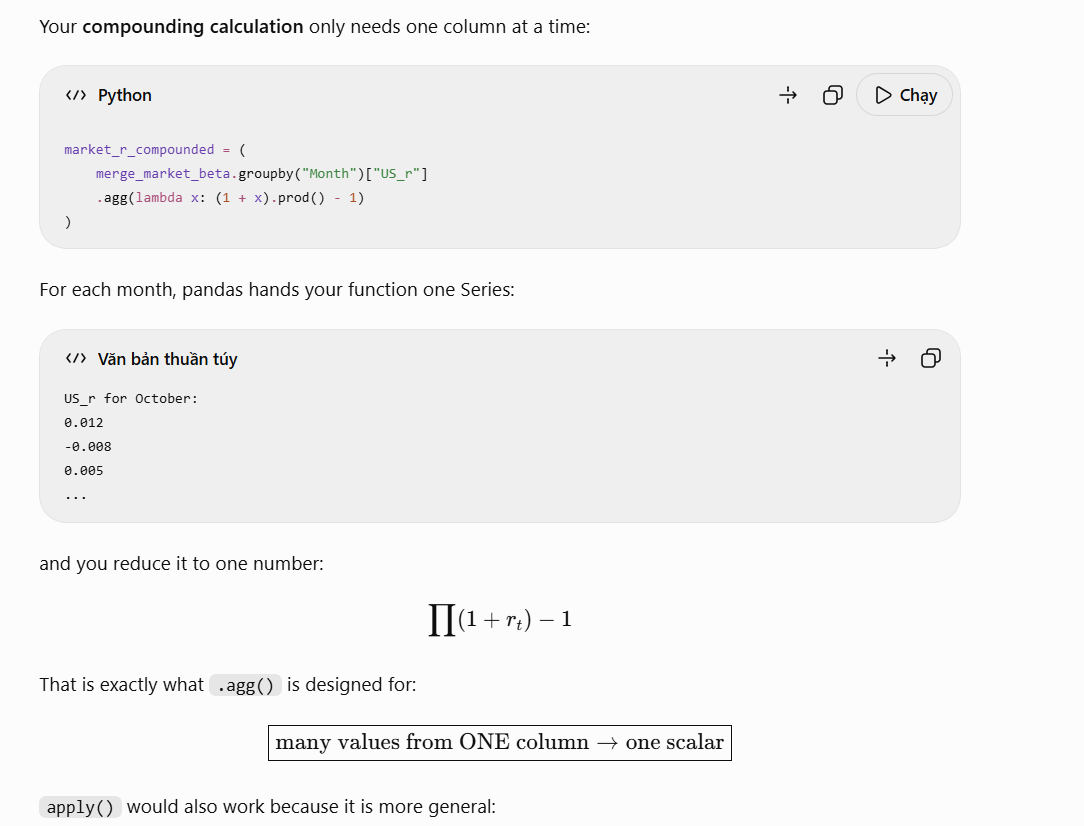

##### 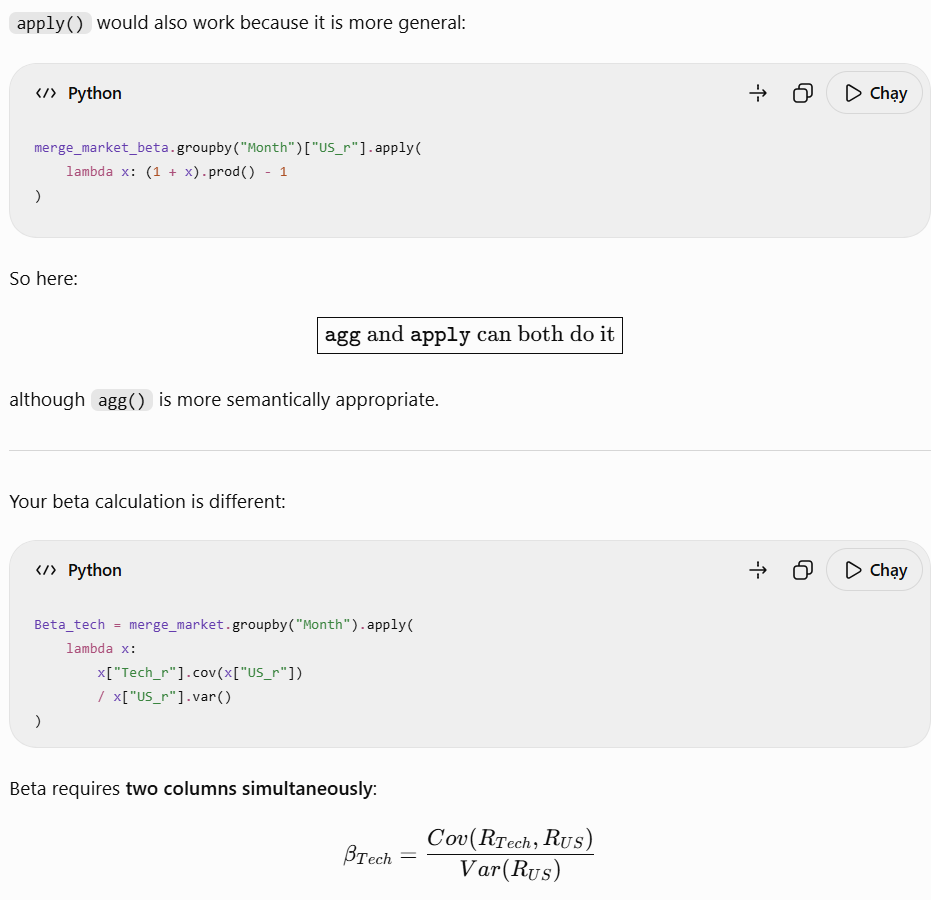

In [44]:
monthly_data_tech = monthly_data.copy()
monthly_data_tech = monthly_data_tech.merge(beta_tech, on = "Month").merge(tech_r_compounded, on = "Month").merge(portfolio_compounded, on = "Month")
monthly_data_tech = monthly_data_tech.rename(columns = {0: "Tech_beta"})
monthly_data_tech = monthly_data_tech.drop(columns = ["P_ret", "α", "Positive Alpha"])
monthly_data_tech

,Month,p_ret_compound,b_ret_compound,Beta,Tech_beta,QQQ_ret
0,2021-11,0.001385,-0.007343,1.020862,0.828585,0.019968
1,2021-12,0.036390,0.045603,1.076581,0.783212,0.011523
2,2022-01,-0.063970,-0.052409,1.090224,0.684280,-0.087470
3,2022-02,-0.024879,-0.029805,1.045363,0.732978,-0.044760
4,2022-03,0.036232,0.037892,1.109687,0.786170,0.046679
5,2022-04,-0.100704,-0.087844,1.111085,0.720945,-0.135958
6,2022-05,-0.001827,0.002588,1.024083,0.740056,-0.015865
7,2022-06,-0.072931,-0.082645,1.009842,0.803326,-0.089079
8,2022-07,0.087409,0.091991,1.011283,0.741768,0.125517
9,2022-08,-0.053068,-0.041289,1.075402,0.801635,-0.051322


In [45]:
monthly_data_tech["UPDATED α"] = monthly_data_tech["p_ret_compound"] - (rf_rates_monthly + monthly_data_tech["Beta"]*(monthly_data_tech["b_ret_compound"]-rf_rates_monthly)) - (monthly_data_tech["Tech_beta"]*(monthly_data_tech["QQQ_ret"]- rf_rates_monthly))
monthly_data_tech

,Month,p_ret_compound,b_ret_compound,Beta,Tech_beta,QQQ_ret,UPDATED α
0,2021-11,0.001385,-0.007343,1.020862,0.828585,0.019968,-0.004543
1,2021-12,0.036390,0.045603,1.076581,0.783212,0.011523,-0.018570
2,2022-01,-0.063970,-0.052409,1.090224,0.684280,-0.087470,0.055867
3,2022-02,-0.024879,-0.029805,1.045363,0.732978,-0.044760,0.041946
4,2022-03,0.036232,0.037892,1.109687,0.786170,0.046679,-0.039221
5,2022-04,-0.100704,-0.087844,1.111085,0.720945,-0.135958,0.097973
6,2022-05,-0.001827,0.002588,1.024083,0.740056,-0.015865,0.010072
7,2022-06,-0.072931,-0.082645,1.009842,0.803326,-0.089079,0.085075
8,2022-07,0.087409,0.091991,1.011283,0.741768,0.125517,-0.095957
9,2022-08,-0.053068,-0.041289,1.075402,0.801635,-0.051322,0.035699


In [46]:
monthly_data

,Month,p_ret_compound,b_ret_compound,Beta,α,Positive Alpha
1,2021-11,0.001385,-0.007343,1.020862,0.008958,True
2,2021-12,0.036390,0.045603,1.076581,-0.012423,False
3,2022-01,-0.063970,-0.052409,1.090224,-0.006502,False
4,2022-02,-0.024879,-0.029805,1.045363,0.006445,True
5,2022-03,0.036232,0.037892,1.109687,-0.005413,False
6,2022-04,-0.100704,-0.087844,1.111085,-0.002694,False
7,2022-05,-0.001827,0.002588,1.024083,-0.004388,False
8,2022-06,-0.072931,-0.082645,1.009842,0.010563,True
9,2022-07,0.087409,0.091991,1.011283,-0.005578,False
10,2022-08,-0.053068,-0.041289,1.075402,-0.008388,False


# 6. Competition prep

In [47]:
stock_data_df

Ticker,AAPL,AVGO,BE,CVS,ETN,GOOGL,GRID,JNJ,MSFT,NVDA,ORCL,SMH,VHT,VOO,VTI,VXUS
Date,,,,,,,,,,,,,,,,
2021-10-01,139.136673,44.611431,18.469999,71.221649,139.407913,135.255920,88.731934,139.557098,277.457184,20.651043,83.581429,124.431725,230.215073,372.080322,210.008682,54.441940
2021-10-04,135.713150,43.567902,16.910000,71.001404,137.288834,132.399612,87.491806,138.470016,271.708374,19.645470,83.134369,121.191040,226.627396,367.503052,206.846252,53.875553
2021-10-05,137.634659,44.434753,18.430000,70.857384,139.972397,134.740829,88.078743,138.783112,277.130890,20.361315,85.211342,122.893860,227.659103,371.073578,208.777298,54.201645
2021-10-06,138.502716,44.742329,18.700001,70.442253,140.379562,136.268295,87.643265,139.070068,281.305634,20.609232,85.071625,123.267403,227.315216,372.723663,209.644867,53.884140
2021-10-07,139.760910,45.212841,19.160000,71.331787,142.433914,137.912674,88.959160,140.313705,282.975555,20.982586,85.975060,124.800430,230.066345,375.930573,211.659882,54.502007
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09,336.640015,361.540009,280.500000,86.160004,429.649994,351.660004,180.889999,261.440002,535.070007,229.279999,141.399994,603.330017,319.010010,715.590027,381.940002,84.820000
2026-10-12,340.970001,354.730011,262.279999,87.739998,426.690002,352.720001,178.699997,263.730011,541.150024,226.320007,137.389999,590.989990,320.670013,715.130005,381.570007,84.440002
2026-10-13,341.269989,357.309998,263.450012,87.550003,428.309998,353.779999,179.250000,248.610001,543.450012,228.520004,143.199997,588.119995,316.369995,715.200012,381.320007,84.540001


In [48]:
stock_returns_df = stock_data_df.pct_change()
stock_returns_df

Ticker,AAPL,AVGO,BE,CVS,ETN,GOOGL,GRID,JNJ,MSFT,NVDA,ORCL,SMH,VHT,VOO,VTI,VXUS
Date,,,,,,,,,,,,,,,,
2021-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-04,-0.024605,-0.023392,-0.084461,-0.003092,-0.015201,-0.021118,-0.013976,-0.007790,-0.020720,-0.048694,-0.005349,-0.026044,-0.015584,-0.012302,-0.015059,-0.010404
2021-10-05,0.014159,0.019897,0.089888,-0.002028,0.019547,0.017683,0.006708,0.002261,0.019957,0.036438,0.024983,0.014051,0.004552,0.009716,0.009336,0.006053
2021-10-06,0.006307,0.006922,0.014650,-0.005859,0.002909,0.011336,-0.004944,0.002068,0.015064,0.012176,-0.001640,0.003040,-0.001511,0.004447,0.004155,-0.005858
2021-10-07,0.009084,0.010516,0.024599,0.012628,0.014634,0.012067,0.015014,0.008943,0.005936,0.018116,0.010620,0.012437,0.012103,0.008604,0.009612,0.011467
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09,-0.011104,0.003887,0.028150,-0.018679,0.012108,0.009676,0.014754,0.019339,0.023842,-0.005207,0.045935,-0.006488,0.016441,0.006059,0.006270,0.008561
2026-10-12,0.012862,-0.018836,-0.064955,0.018338,-0.006889,0.003014,-0.012107,0.008759,0.011363,-0.012910,-0.028359,-0.020453,0.005204,-0.000643,-0.000969,-0.004480
2026-10-13,0.000880,0.007273,0.004461,-0.002165,0.003797,0.003005,0.003078,-0.057331,0.004250,0.009721,0.042288,-0.004856,-0.013409,0.000098,-0.000655,0.001184


In [49]:
volatility_df = stock_returns_df.std()
volatility_df

Ticker
AAPL     0.017618
AVGO     0.027944
BE       0.056345
CVS      0.019116
ETN      0.020144
GOOGL    0.020203
GRID     0.013815
JNJ      0.011235
MSFT     0.017722
NVDA     0.032650
ORCL     0.027765
SMH      0.023171
VHT      0.009708
VOO      0.010626
VTI      0.010990
VXUS     0.010295
dtype: float64

In [50]:
sma_exp = stock_returns_df.expanding().mean()
rolling_vol_df = stock_returns_df.groupby("Date").apply(lambda x: x.rolling(30).mean().combine_first(sma_exp))
rolling_vol_df

Ticker                     AAPL      AVGO        BE       CVS       ETN  \
Date       Date                                                           
2021-10-01 2021-10-01       NaN       NaN       NaN       NaN       NaN   
           2021-10-04 -0.024605 -0.023392 -0.084461 -0.003092 -0.015201   
           2021-10-05 -0.005223 -0.001747  0.002713 -0.002560  0.002173   
           2021-10-06 -0.001380  0.001142  0.006692 -0.003660  0.002418   
           2021-10-07  0.001236  0.003486  0.011169  0.000412  0.005472   
...                         ...       ...       ...       ...       ...   
2026-10-15 2026-10-09  0.000856  0.002048  0.003682  0.000335  0.001097   
           2026-10-12  0.000866  0.002032  0.003628  0.000350  0.001091   
           2026-10-13  0.000866  0.002036  0.003628  0.000348  0.001093   
           2026-10-14  0.000869  0.002010  0.003553  0.000373  0.001056   
           2026-10-15  0.000866  0.002004  0.003540  0.000392  0.001043   

Ticker                    GOOGL      GRID       JNJ      MSFT      NVDA  \
Date       Date                                                           
2021-10-01 2021-10-01       NaN       NaN       NaN       NaN       NaN   
           2021-10-04 -0.021118 -0.013976 -0.007790 -0.020720 -0.048694   
           2021-10-05 -0.001717 -0.003634 -0.002764 -0.000381 -0.006128   
           2021-10-06  0.002634 -0.004071 -0.001154  0.004767 -0.000027   
           2021-10-07  0.004992  0.000701  0.001370  0.005059  0.004509   
...                         ...       ...       ...       ...       ...   
2026-10-15 2026-10-09  0.000963  0.000661  0.000560  0.000678  0.002440   
           2026-10-12  0.000964  0.000650  0.000566  0.000686  0.002428   
           2026-10-13  0.000966  0.000652  0.000521  0.000689  0.002434   
           2026-10-14  0.000951  0.000631  0.000537  0.000674  0.002407   
           2026-10-15  0.000954  0.000620  0.000535  0.000682  0.002390   

Ticker                     ORCL       SMH       VHT       VOO       VTI  \
Date       Date                                                           
2021-10-01 2021-10-01       NaN       NaN       NaN       NaN       NaN   
           2021-10-04 -0.005349 -0.026044 -0.015584 -0.012302 -0.015059   
           2021-10-05  0.009817 -0.005997 -0.005516 -0.001293 -0.002861   
           2021-10-06  0.005998 -0.002985 -0.004181  0.000620 -0.000522   
           2021-10-07  0.007154  0.000871 -0.000110  0.002616  0.002011   
...                         ...       ...       ...       ...       ...   
2026-10-15 2026-10-09  0.000788  0.001521  0.000306  0.000576  0.000535   
           2026-10-12  0.000765  0.001504  0.000310  0.000575  0.000534   
           2026-10-13  0.000798  0.001499  0.000299  0.000574  0.000533   
           2026-10-14  0.000727  0.001466  0.000316  0.000565  0.000523   
           2026-10-15  0.000750  0.001457  0.000330  0.000567  0.000526   

Ticker                     VXUS  
Date       Date                  
2021-10-01 2021-10-01       NaN  
           2021-10-04 -0.010404  
           2021-10-05 -0.002175  
           2021-10-06 -0.003403  
           2021-10-07  0.000314  
...                         ...  
2026-10-15 2026-10-09  0.000405  
           2026-10-12  0.000401  
           2026-10-13  0.000402  
           2026-10-14  0.000392  
           2026-10-15  0.000395  

[1600225 rows x 16 columns]

In [51]:
rolling_vol_df.mean()

Ticker
AAPL     0.000802
AVGO     0.001863
BE       0.002234
CVS      0.000435
ETN      0.000984
GOOGL    0.000314
GRID     0.000396
JNJ      0.000328
MSFT     0.000611
NVDA     0.002349
ORCL     0.000660
SMH      0.000899
VHT      0.000142
VOO      0.000354
VTI      0.000255
VXUS     0.000021
dtype: float64

# --------------------------------------------------------

In [52]:
portfolio["p_ret"] = portfolio["Portfolio"].pct_change()
portfolio.dropna(inplace = True)
portfolio

,Portfolio,Month,p_ret
Date,,,
2021-10-04,8721.765192,2021-10,-0.016584
2021-10-05,8828.214362,2021-10,0.012205
2021-10-06,8865.818168,2021-10,0.004260
2021-10-07,8957.375102,2021-10,0.010327
2021-10-08,8944.275062,2021-10,-0.001462
...,...,...,...
2026-10-09,21508.571505,2026-10,0.006670
2026-10-12,21442.558062,2026-10,-0.003069
2026-10-13,21489.098726,2026-10,0.002170


In [53]:
annualized_ret = (1 + portfolio["p_ret"]).prod()**(252 / len(portfolio)) - 1

annualized_vol = portfolio["p_ret"].std() * np.sqrt(252)
Sharpe_ratio = (portfolio["p_ret"].mean() - rf_rates_daily) / portfolio["p_ret"].std() * np.sqrt(252)

cumret = (1 + portfolio["p_ret"]).cumprod()
peak = cumret.cummax()
dd = cumret/peak - 1
max_dd = dd.min()


annual_data = pd.DataFrame({"Annualized Returns": annualized_ret, "Annualized Volatility": annualized_vol, "Sharpe Ratio": Sharpe_ratio, "Max Drawdown": max_dd}, index = ["Portfolio"])
annual_data

,Annualized Returns,Annualized Volatility,Sharpe Ratio,Max Drawdown
Portfolio,0.188561,0.200672,0.741834,-0.275027


In [54]:
portfolio_vol_monthly = pd.DataFrame(portfolio.groupby("Month")["p_ret"].apply(lambda x: x.std()))
portfolio_vol_monthly.rename(columns = {"p_ret": "P_month_vol"}, inplace = True)

In [55]:
portfolio_ret_monthly = portfolio.groupby("Month")["Portfolio"].agg(["first", "last"]).reset_index()
portfolio_ret_monthly["P_month_ret"] = portfolio_ret_monthly["last"] / portfolio_ret_monthly["first"] - 1
portfolio_ret_monthly

,Month,first,last,P_month_ret
0,2021-10,8721.765192,9545.465368,0.094442
1,2021-11,9547.456237,9558.681849,0.001176
2,2021-12,9468.525483,9906.525255,0.046258
3,2022-01,9941.098206,9272.800927,-0.067226
4,2022-02,9315.776615,9042.105616,-0.029377
...,...,...,...,...
56,2026-06,21084.560698,19948.813516,-0.053866
57,2026-07,19872.555895,20268.389840,0.019919
58,2026-08,20736.102347,21008.633862,0.013143
59,2026-09,20838.103125,21179.515539,0.016384


In [56]:
portfolio_monthly_data_df = portfolio_vol_monthly.merge(portfolio_ret_monthly, on = "Month")
portfolio_monthly_data_df

,Month,P_month_vol,first,last,P_month_ret
0,2021-10,0.007286,8721.765192,9545.465368,0.094442
1,2021-11,0.008982,9547.456237,9558.681849,0.001176
2,2021-12,0.011937,9468.525483,9906.525255,0.046258
3,2022-01,0.012648,9941.098206,9272.800927,-0.067226
4,2022-02,0.015796,9315.776615,9042.105616,-0.029377
...,...,...,...,...,...
56,2026-06,0.015248,21084.560698,19948.813516,-0.053866
57,2026-07,0.011840,19872.555895,20268.389840,0.019919
58,2026-08,0.010111,20736.102347,21008.633862,0.013143
59,2026-09,0.008685,20838.103125,21179.515539,0.016384


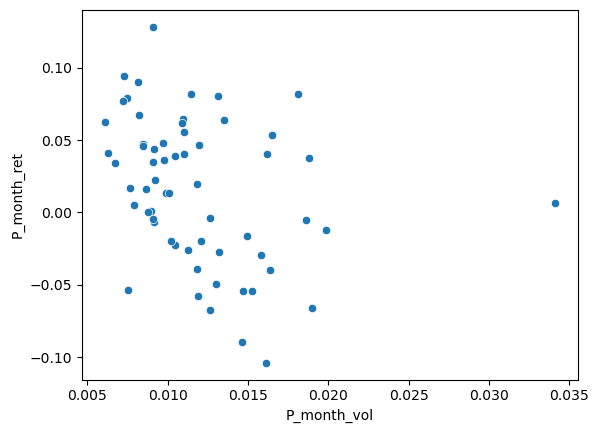

In [57]:
sns.scatterplot(data = portfolio_monthly_data_df, x = "P_month_vol", y = "P_month_ret")
plt.show()

In [58]:
annual_data["Sharpe Ratio"]

Portfolio    0.741834
Name: Sharpe Ratio, dtype: float64

In [59]:
stock_returns_df.corr()

Ticker,AAPL,AVGO,BE,CVS,ETN,GOOGL,GRID,JNJ,MSFT,NVDA,ORCL,SMH,VHT,VOO,VTI,VXUS
Ticker,,,,,,,,,,,,,,,,
AAPL,1.000000,0.403301,0.198195,0.144664,0.320941,0.512566,0.495997,0.137190,0.526029,0.467545,0.233041,0.516959,0.454439,0.713209,0.702306,0.519498
AVGO,0.403301,1.000000,0.361864,0.035009,0.564984,0.416671,0.605827,-0.116946,0.438545,0.624005,0.466771,0.766690,0.229240,0.636521,0.629230,0.500922
BE,0.198195,0.361864,1.000000,0.029853,0.407922,0.248525,0.537559,-0.043343,0.225620,0.332948,0.302872,0.446129,0.189310,0.421364,0.438811,0.424190
CVS,0.144664,0.035009,0.029853,1.000000,0.111598,0.081554,0.143149,0.210343,0.089862,0.039777,0.047116,0.081483,0.381251,0.245169,0.243142,0.164690
ETN,0.320941,0.564984,0.407922,0.111598,1.000000,0.356718,0.776779,-0.064553,0.360966,0.524789,0.423303,0.685361,0.292798,0.649726,0.652124,0.557724
GOOGL,0.512566,0.416671,0.248525,0.081554,0.356718,1.000000,0.497680,0.049563,0.545073,0.491832,0.300286,0.529963,0.364773,0.668457,0.655091,0.497372
GRID,0.495997,0.605827,0.537559,0.143149,0.776779,0.497680,1.000000,0.032648,0.481015,0.637470,0.466118,0.811437,0.473019,0.836620,0.846183,0.860985
JNJ,0.137190,-0.116946,-0.043343,0.210343,-0.064553,0.049563,0.032648,1.000000,-0.010253,-0.120278,-0.081490,-0.103959,0.555630,0.150544,0.142213,0.134012
MSFT,0.526029,0.438545,0.225620,0.089862,0.360966,0.545073,0.481015,-0.010253,1.000000,0.556792,0.448874,0.526783,0.359416,0.690761,0.673542,0.461535


In [60]:
sma_exp_p = portfolio["p_ret"].expanding().mean()

portfolio["rolling_vol_20"] = portfolio["p_ret"].rolling(20).std()
portfolio["rolling_ret_20"] = portfolio["p_ret"].rolling(20).mean()
portfolio

,Portfolio,Month,p_ret,rolling_vol_20,rolling_ret_20
Date,,,,,
2021-10-04,8721.765192,2021-10,-0.016584,NaN,NaN
2021-10-05,8828.214362,2021-10,0.012205,NaN,NaN
2021-10-06,8865.818168,2021-10,0.004260,NaN,NaN
2021-10-07,8957.375102,2021-10,0.010327,NaN,NaN
2021-10-08,8944.275062,2021-10,-0.001462,NaN,NaN
...,...,...,...,...,...
2026-10-09,21508.571505,2026-10,0.006670,0.008663,0.001326
2026-10-12,21442.558062,2026-10,-0.003069,0.008171,0.001764
2026-10-13,21489.098726,2026-10,0.002170,0.008040,0.002093


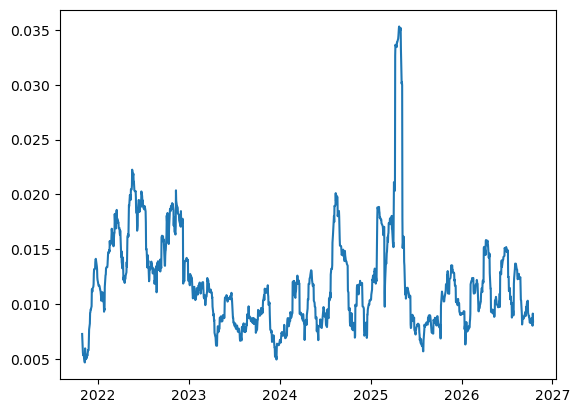

In [61]:
plt.plot(portfolio.index, portfolio["rolling_vol_20"])
plt.show()

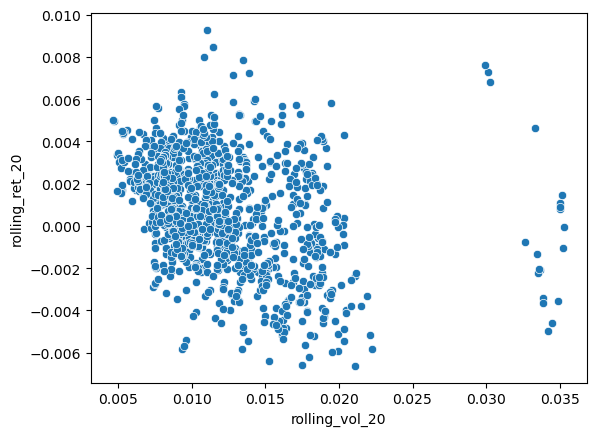

In [62]:
# Risk-to-return

sns.scatterplot( data = portfolio, x = "rolling_vol_20", y = "rolling_ret_20")
plt.show()

In [63]:
def trailing(daily_ret, trailing_days = 60):
    
    trailing = daily_ret.iloc[-trailing_days:]
    vol = trailing.std()

    inv = (1/vol).replace([np.inf, -np.inf], np.nan).dropna()
    weights = inv / inv.sum()

    return weights

vol_weights = pd.DataFrame(trailing(stock_returns_df)).rename(columns = {0: "Weights"})
vol_weights

,Weights
Ticker,
AAPL,0.059066
AVGO,0.040598
BE,0.014950
CVS,0.054639
ETN,0.033942
GOOGL,0.047037
GRID,0.060073
JNJ,0.066325
MSFT,0.038412


In [64]:
portfolio.tail()

,Portfolio,Month,p_ret,rolling_vol_20,rolling_ret_20
Date,,,,,
2026-10-09,21508.571505,2026-10,0.006670,0.008663,0.001326
2026-10-12,21442.558062,2026-10,-0.003069,0.008171,0.001764
2026-10-13,21489.098726,2026-10,0.002170,0.008040,0.002093
2026-10-14,21114.173947,2026-10,-0.017447,0.009144,0.001249
2026-10-15,21094.343352,2026-10,-0.000939,0.008430,0.000384


# 7. Monte Carlo  - for alternate portfolio weights

In [65]:
import random
N = 10000

tickerz = stock_returns_df.columns


monte_carlo_ret = []
monte_carlo_vol = []


hist = stock_returns_df.tail(120).dropna()
mu = hist.mean() # Estimating a stocks return based on average historical data
cov = hist.cov()

for i in range(N):
    weights = []
    for i in range(len(vol_weights)):
        w = random.randint(1,100)
        weights.append(w)

        
        
    total = sum(weights)
    if total == 0:
         continue
    weights_percent = pd.Series(np.array(weights) / total, index=tickerz)

    stocks_weigh_ret = mu @ weights_percent # We are weighing the last recorded daily return and weigh it to form the portfolio
# ADDRESS THE 2 PICS BELOW

    volatility = (hist @ weights_percent).std()
    
    monte_carlo_ret.append(stocks_weigh_ret)
    monte_carlo_vol.append(volatility)

monte_carlo_result = pd.DataFrame({"Return": monte_carlo_ret,"Volatility": monte_carlo_vol})
monte_carlo_result
# monte_carlo_result["Volatility"] = monte_carlo_vol_df[['2026-10-09']]



# monte_carlo_result.columns = ["Return", "Volatility"]
#v.rename(columns = {'2026-10-09': "Daily Ret"}, inplace = True)

###


,Return,Volatility
0,0.000995,0.012483
1,0.000697,0.012478
2,0.000444,0.014412
3,0.000799,0.014076
4,0.001047,0.015194
...,...,...
9995,0.000853,0.015154
9996,0.000627,0.012697
9997,0.000739,0.012222
9998,0.000953,0.012560


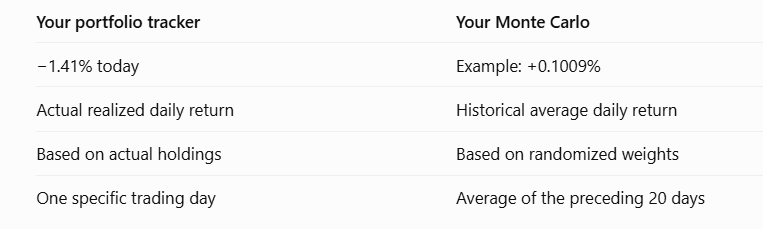
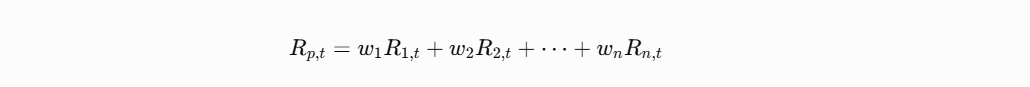

In [66]:
### NEXT STEP: INCLUDE STD IN THE MONTE CARLO (WE CURRENTLY HAVE RETURN)
monte_carlo_result

,Return,Volatility
0,0.000995,0.012483
1,0.000697,0.012478
2,0.000444,0.014412
3,0.000799,0.014076
4,0.001047,0.015194
...,...,...
9995,0.000853,0.015154
9996,0.000627,0.012697
9997,0.000739,0.012222
9998,0.000953,0.012560


In [67]:
monte_carlo_result.to_csv("Monte Carlo Simulation")

In [68]:
monte_carlo_df = pd.read_csv("Monte Carlo Simulation")
monte_carlo_df

,Unnamed: 0,Return,Volatility
0,0,0.000995,0.012483
1,1,0.000697,0.012478
2,2,0.000444,0.014412
3,3,0.000799,0.014076
4,4,0.001047,0.015194
...,...,...,...
9995,9995,0.000853,0.015154
9996,9996,0.000627,0.012697
9997,9997,0.000739,0.012222
9998,9998,0.000953,0.012560


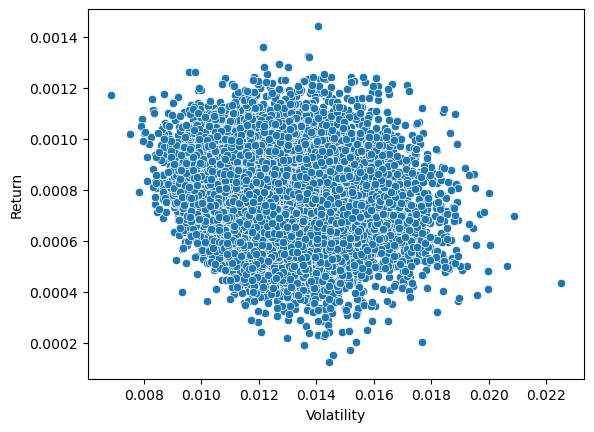

In [69]:
sns.scatterplot( data = monte_carlo_result, x = "Volatility", y = "Return")
plt.show()

In [70]:
# SOLVING FOR OPTIMAL WEIGHTS

from scipy.optimize import minimize

n = len(tickerz)

initial_weights = np.ones(n) / n
bounds = [(0, 1)] * n

constraints = [
    {"type": "eq", "fun": lambda w: sum(w) - 1} # eq is = 0, ine is != 0; test the function "fun"
]


def port_var(w):
    return float(w @ cov @ w) 
def port_ret(w):
    return float(w @ mu) # short for p.dot(w)

def port_vol(w):
    return np.sqrt(max(float(port_var(w)), 0))
    
def negative_sharpe(w):
    return -((port_ret(w) - rf_rates_daily) / port_vol(w))


min_var = minimize(port_var,initial_weights, bounds=bounds,constraints=constraints, method="SLSQP")


# The algorithm here is SLSQP (Sequential Least Squares Programming), which is a constrained nonlinear optimization method.

# => it searches systematically for a solution to the optimization problem.

max_sharpe = minimize(
    negative_sharpe,
    initial_weights,
    bounds=bounds,
    constraints=constraints,
    method="SLSQP",
    options={"maxiter": 2000, "ftol": 1e-12}
)



In [71]:
optimal_weights = pd.DataFrame({
    "Minimum Volatility": min_var.x * 100,
    "Maximum Sharpe": max_sharpe.x * 100
}, index=tickerz)

optimal_weights

,Minimum Volatility,Maximum Sharpe
Ticker,,
AAPL,8.151856e+00,1.689728e+01
AVGO,5.194301e+00,2.954422e-15
BE,1.387779e-15,1.533252e+00
CVS,8.253266e+00,9.010693e+00
ETN,4.986878e+00,0.000000e+00
GOOGL,7.043753e+00,4.193422e-16
GRID,5.893979e+00,0.000000e+00
JNJ,8.998466e+00,0.000000e+00
MSFT,7.174340e+00,1.256194e+01


In [72]:
optimal_weights["Minimum Volatility"]-optimal_weights["Maximum Sharpe"]

Ticker
AAPL     -8.745428
AVGO      5.194301
BE       -1.533252
CVS      -0.757427
ETN       4.986878
GOOGL     7.043753
GRID      5.893979
JNJ       8.998466
MSFT     -5.387599
NVDA      5.846690
ORCL      4.238331
SMH      -4.792526
VHT     -42.189565
VOO       7.204956
VTI       7.192656
VXUS      6.805788
dtype: float64

In [73]:
optimal_weight = optimal_weights[["Maximum Sharpe"]]
optimal_port = stock_data_df @ optimal_weight
optimal_port.rename(columns = {"Maximum Sharpe": "Optimal Sharpe Returns"}, inplace = True)

In [74]:
optimal_port["Returns"] = optimal_port["Optimal Sharpe Returns"].pct_change()
optimal_port["Month"] = optimal_port.index.to_period("M")
optimal_port

,Optimal Sharpe Returns,Returns,Month
Date,,,
2021-10-01,19334.697151,NaN,2021-10
2021-10-04,18988.234712,-0.017919,2021-10
2021-10-05,19157.994939,0.008940,2021-10
2021-10-06,19207.820297,0.002601,2021-10
2021-10-07,19412.506809,0.010656,2021-10
...,...,...,...
2026-10-09,35400.561682,0.008966,2026-10
2026-10-12,35505.772648,0.002972,2026-10
2026-10-13,35295.130324,-0.005933,2026-10


In [75]:
monthly_returns = pd.DataFrame(optimal_port.groupby("Month")["Returns"].apply(lambda x: (1 + x).prod() -1 )).tail(10)
monthly_returns

,Returns
Month,
2026-01,-0.014985
2026-02,0.004174
2026-03,-0.065219
2026-04,0.083410
2026-05,0.086162
2026-06,0.010885
2026-07,0.017593
2026-08,0.046004
2026-09,0.020957


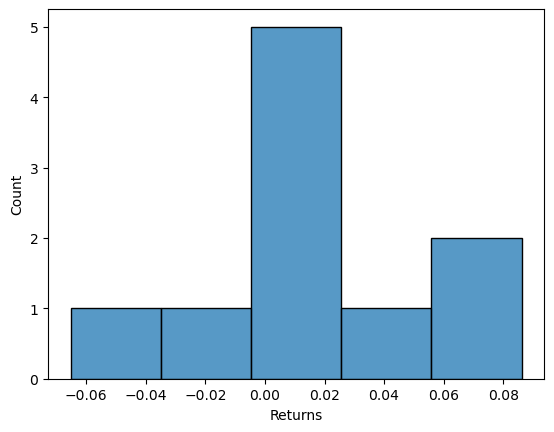

In [76]:
sns.histplot(data = monthly_returns, x = "Returns")
plt.show()

# 8. Stock Position Adjustments

In [77]:
cov_df = hist.cov()
weight = pd.Series(max_sharpe.x, index = tickerz)
                        

p_var = float(weight @ cov_df @ weight)

risk_contribution = (weight * (cov_df @ weight)) / p_var

risk_df = pd.DataFrame({
    "Weight (%)": weight * 100,
    "Variance Contribution (%)": risk_contribution * 100
})

In [78]:
risk_df

,Weight (%),Variance Contribution (%)
Ticker,,
AAPL,1.689728e+01,1.950991e+01
AVGO,2.954422e-15,4.098204e-17
BE,1.533252e+00,2.179675e+00
CVS,9.010693e+00,8.032799e+00
ETN,0.000000e+00,0.000000e+00
GOOGL,4.193422e-16,2.543190e-16
GRID,0.000000e+00,0.000000e+00
JNJ,0.000000e+00,0.000000e+00
MSFT,1.256194e+01,1.594753e+01


In [79]:
cova  = cov_df @ weight
cova

Ticker
AAPL     6.385730e-05
AVGO     7.671729e-07
BE       7.862313e-05
CVS      4.930386e-05
ETN      5.475848e-06
GOOGL    3.354150e-05
GRID     2.570615e-05
JNJ      3.313636e-05
MSFT     7.021162e-05
NVDA     2.303971e-05
ORCL     6.058915e-05
SMH      3.509266e-05
VHT      5.283272e-05
VOO      2.977382e-05
VTI      3.116731e-05
VXUS     3.539916e-05
dtype: float64

In [80]:
## NEXT STEPS: VALIDATE WHETHER THE WEIGHTS ARE CORRECT AND THEN CHECK THE VARIANCE CONTRIBUTION (cont)

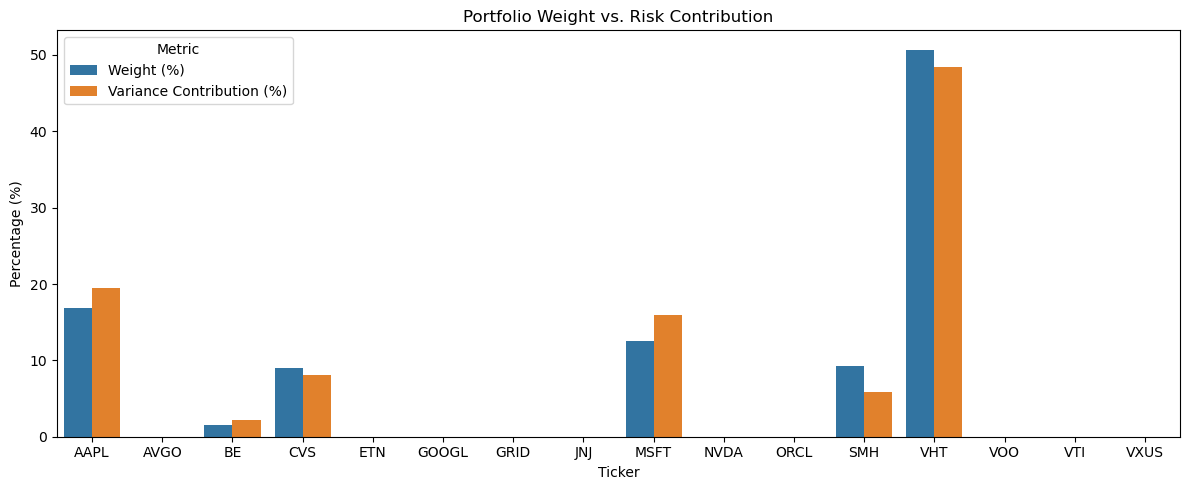

In [81]:
fig, ax = plt.subplots(figsize=(12, 5))

# Prepare data for plotting
plot_df = risk_df.reset_index()

plot_df = plot_df.melt(
    id_vars="Ticker",
    value_vars=["Weight (%)", "Variance Contribution (%)"],
    var_name="Metric",
    value_name="Percentage"
)

sns.barplot(
    data=plot_df,
    x="Ticker",
    y="Percentage",
    hue="Metric",
    ax=ax
)

ax.set_title("Portfolio Weight vs. Risk Contribution")
ax.set_ylabel("Percentage (%)")

plt.tight_layout()
plt.show()


In [82]:
portfolio

,Portfolio,Month,p_ret,rolling_vol_20,rolling_ret_20
Date,,,,,
2021-10-04,8721.765192,2021-10,-0.016584,NaN,NaN
2021-10-05,8828.214362,2021-10,0.012205,NaN,NaN
2021-10-06,8865.818168,2021-10,0.004260,NaN,NaN
2021-10-07,8957.375102,2021-10,0.010327,NaN,NaN
2021-10-08,8944.275062,2021-10,-0.001462,NaN,NaN
...,...,...,...,...,...
2026-10-09,21508.571505,2026-10,0.006670,0.008663,0.001326
2026-10-12,21442.558062,2026-10,-0.003069,0.008171,0.001764
2026-10-13,21489.098726,2026-10,0.002170,0.008040,0.002093


# 9. Determining the good volatility and bad volatility to determine stock reallocations

In [83]:
cumprod_data = (1 + stock_returns_df[stock_returns_df.columns]).cumprod()
cummax_data = cumprod_data.cummax()

stock_drawdown = cumprod_data/cummax_data -1
stock_drawdown

Ticker,AAPL,AVGO,BE,CVS,ETN,GOOGL,GRID,JNJ,MSFT,NVDA,ORCL,SMH,VHT,VOO,VTI,VXUS
Date,,,,,,,,,,,,,,,,
2021-10-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-10-04,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2021-10-05,0.000000,0.000000,0.000000,-0.002028,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2021-10-06,0.000000,0.000000,0.000000,-0.007875,0.000000,0.000000,-0.004944,0.000000,0.000000,0.000000,-0.001640,0.000000,-0.001511,0.000000,0.000000,-0.005858
2021-10-07,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09,-0.012989,-0.246690,-0.188955,-0.216154,-0.065897,-0.125487,-0.089202,-0.061021,-0.004792,-0.041632,-0.562816,-0.098040,-0.028838,-0.000852,-0.003633,-0.038873
2026-10-12,-0.000293,-0.260879,-0.241637,-0.201779,-0.072332,-0.122851,-0.100229,-0.052796,0.000000,-0.054004,-0.575214,-0.116488,-0.023785,-0.001494,-0.004598,-0.043179
2026-10-13,0.000000,-0.255504,-0.238254,-0.203508,-0.068810,-0.120215,-0.097460,-0.107101,0.000000,-0.044809,-0.557251,-0.120779,-0.036875,-0.001396,-0.005250,-0.042046


In [84]:
stock_drawdown_120_max = stock_drawdown.tail(120).min()
stock_drawdown_120_max

Ticker
AAPL    -0.127062
AVGO    -0.294377
BE      -0.526529
CVS     -0.226252
ETN     -0.169581
GOOGL   -0.210472
GRID    -0.158179
JNJ     -0.109591
MSFT    -0.344984
NVDA    -0.193046
ORCL    -0.645781
SMH     -0.246206
VHT     -0.099146
VOO     -0.044697
VTI     -0.043594
VXUS    -0.053641
dtype: float64

In [85]:
# Same 120-day sample as your optimizer
R = hist[tickerz].dropna()

# Retain only negative returns; positive returns become zero
negative_returns = R.clip(upper=0)

# Downside deviation, with a 0% threshold
downside_dev = np.sqrt((negative_returns ** 2).mean())

returns_10 = ((1 + R).rolling(10).apply(np.prod, raw = True)) - 1

downside_df = pd.DataFrame({
    "Downside Deviation (%)": downside_dev * 100,
    "Worst 10-day Return (%)": returns_10.min() * 100,
    "Max Drawdown (%)": stock_drawdown_120_max * 100
})

downside_df

,Downside Deviation (%),Worst 10-day Return (%),Max Drawdown (%)
Ticker,,,
AAPL,1.172507,-10.550085,-12.706222
AVGO,2.232918,-21.774622,-29.437687
BE,4.377670,-33.211318,-52.652885
CVS,1.101385,-14.486919,-22.625187
ETN,2.069272,-12.348007,-16.958099
GOOGL,1.424307,-11.479845,-21.047201
GRID,1.281436,-8.273554,-15.817904
JNJ,1.028541,-7.085999,-10.959122
MSFT,1.196741,-13.215177,-34.498390


# 10. STOCK REALLOCATION

In [86]:

import numpy as np
import pandas as pd

# Same 120-day sample
R = hist.reindex(columns=tickerz).sort_index().dropna().tail(120)

# Starting allocation: your optimized portfolio
w_current = pd.Series(max_sharpe.x, index=tickerz)
w_current = w_current.reindex(R.columns)

assert np.isclose(w_current.sum(), 1)
assert (w_current >= -1e-8).all()

# Adjustable parameters
transfer = 0.02            # Reallocate 2 percentage points
max_weight = 0.35          # 35% maximum per holding
risk_aversion = 0.25       # Penalty on adverse-tail outcomes
max_es_worsening = 0.005   # Allow at most 0.5 pp worsening

# Recalculate current variance contribution
variance = p_var

risk_pct = (
    w_current * (C @ w_current) / variance
) * 100

risk_gap = risk_pct - w_current * 100

# Identify stocks driving disproportionate variance
donors = [
    stock for stock in R.columns
    if risk_gap[stock] > 2
    and w_current[stock] >= transfer
]

print("Positions flagged for review:", donors)

=============================================================

def evaluate(w):
    # Daily constant-weight portfolio returns
    daily = R @ w

    # All historical 10-trading-day returns
    r10 = (
        (1 + daily).rolling(10)
        .apply(np.prod, raw=True)
        .dropna() - 1
    )

    # Average of worst 10% of outcomes
    cutoff = r10.quantile(0.10)
    es10 = r10[r10 <= cutoff].mean()

    upside = r10.clip(lower=0).mean()
    downside = (-r10.clip(upper=0)).mean()

    score = r10.mean() + risk_aversion * es10

    return pd.Series({
        "Mean 10d": r10.mean(),
        "Upside": upside,
        "Downside": downside,
        "Loss frequency": (r10 < 0).mean(),
        "Worst 10d": r10.min(),
        "ES10": es10,
        "Score": score
    })

# Baseline portfolio
baseline = evaluate(w_current)

# Evaluate possible transfers
candidates = []

for donor in donors:
    for receiver in R.columns:

        if receiver == donor:
            continue

        if w_current[receiver] + transfer > max_weight:
            continue

        w_new = w_current.copy()

        w_new[donor] -= transfer
        w_new[receiver] += transfer

        result = evaluate(w_new)

        # Guardrail: limit deterioration in tail losses
        if result["ES10"] < baseline["ES10"] - max_es_worsening:
            continue

        candidates.append({
            "Sell": donor,
            "Buy": receiver,
            "Score change (pp)":
                (result["Score"] - baseline["Score"]) * 100,
            "Return change (pp)":
                (result["Mean 10d"] - baseline["Mean 10d"]) * 100,
            "ES improvement (pp)":
                (result["ES10"] - baseline["ES10"]) * 100,
            "Loss probability change (pp)":
                (result["Loss frequency"] -
                 baseline["Loss frequency"]) * 100
        })

candidate_df = pd.DataFrame(candidates)

if candidate_df.empty:
    print("No candidate transfers met the constraints.")
else:
    candidate_df = candidate_df.sort_values(
        "Score change (pp)", ascending=False
    )

    display(candidate_df.head(10).round(3))

SyntaxError: invalid syntax (1902793148.py, line 38)

In [87]:
risk_df.to_csv("Risk Cont")
optimal_weights.to_csv("Best Risk_adjusted Weights")